In [1]:
# Cell 1 — Imports
import numpy as np
import pandas as pd
import xarray as xr
import sys
import matplotlib.pyplot as plt
from pathlib import Path
import glob
sys.path.append(str(Path("../src").resolve()))
from radar_lwc.preprocessing.chirps import combine_chirps
from radar_lwc.preprocessing.get_reflectivity import get_reflectivity
from radar_lwc.preprocessing.clean import drop_duplicate_times
from radar_lwc.preprocessing.align import align_to_reference_time

## WHICH DAY /DATASET

In [2]:
Dataset_94GHz = "20230930_94GHz"
Dataset_35GHz = "20230930_35GHz"
Processed_Dataset = "20230930"

Load Both Radars

In [3]:
 # Cell 2 — Load both
def load_rpg(folder):
     files = sorted(glob.glob(str(Path(folder) / "*ZEN.LV1.nc")))
     ds = xr.open_mfdataset(files, combine="by_coords")    # Combine="by_coords" orders them immediately by coordinates, in this case by the time so it is immediately in structure 7:01...7:02...7:03
     epoch = pd.Timestamp("2001-01-01")
     ds = ds.assign_coords(Time=("Time", epoch + pd.to_timedelta(ds.Time.values, unit="s")))
     ds = drop_duplicate_times(ds)
     return ds

ds_w  = load_rpg(f"../data/raw/cmtrace/{Dataset_94GHz}")
ds_ka = load_rpg(f"../data/raw/cmtrace/{Dataset_35GHz}")

C:\Users\geron\AppData\Local\Temp\ipykernel_23896\3530811634.py:4: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds = xr.open_mfdataset(files, combine="by_coords")    # Combine="by_coords" orders them immediately by coordinates, in this case by the time so it is immediately in structure 7:01...7:02...7:03
C:\Users\geron\AppData\Local\Temp\ipykernel_23896\3530811634.py:4: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid

In [4]:
with ds_ka as d:
    for v in ["SeqIntTime", "AvgNum", "DoppLen", "MaxVel"]:
        print(f"{v:12s} {np.asarray(d[v].values).ravel()}")

SeqIntTime   [0.03434201 0.13736804 0.27473608 ... 0.03434201 0.13736804 0.27473608]
AvgNum       [3072 3072 3072 ... 3072 3072 3072]
DoppLen      [512 512 256 ... 512 512 256]
MaxVel       [30.136211 26.609169 12.592745 ... 30.136211 26.609169 12.592745]


In [16]:

c   = 299792458.0
lam = c / (float(ds_ka["Freq"].values.flat[0]) * 1e9)

max_vel = ds_ka["MaxVel"].values[0, :]
avg_num = ds_ka["AvgNum"].values[0, :].astype(float)
seq_int = ds_ka["SeqIntTime"].values[0, :]

T_chirp = seq_int / avg_num
print("lambda [mm]      :", lam * 1000)
print("chirp spacing [us]:", T_chirp * 1e6)
print("PRF from MaxVel  :", 4.0 * max_vel / lam)
print("AvgNum  :", avg_num )
print("v_Nyq implied    :", lam / (4.0 * T_chirp))

lambda [mm]      : 8.5654988
chirp spacing [us]: [11.17903957 44.7161583  89.4323166 ]
PRF from MaxVel  : [14073.302  12426.209   5880.6826]
AvgNum  : [3072. 3072. 3072.]
v_Nyq implied    : [191.55265402  47.88816351  23.94408175]


In [15]:

c   = 299792458.0
lam = c / (float(ds_w["Freq"].values.flat[0]) * 1e9)

max_vel = ds_w["MaxVel"].values[0, :]
avg_num = ds_w["AvgNum"].values[0, :].astype(float)
seq_int = ds_w["SeqIntTime"].values[0, :]

T_chirp = seq_int / avg_num
print("lambda [mm]      :", lam * 1000)
print("chirp spacing [us]:", T_chirp * 1e6)
print("PRF from MaxVel  :", 4.0 * max_vel / lam)
print("AvgNum  :", avg_num)
print("v_Nyq implied    :", lam / (4.0 * T_chirp))

lambda [mm]      : 3.189281468085106
chirp spacing [us]: [11.17903957 44.7161583  89.4323166 ]
PRF from MaxVel  : [14072.292  12425.317   5880.2607]
AvgNum  : [3072. 3072. 3072.]
v_Nyq implied    : [71.32279671 17.83069918  8.91534959]


In [ ]:
import glob
import numpy as np
import xarray as xr
from pathlib import Path


def check_range_sampling(folder, label=""):
    """
    Compare RPG's reported range resolution with the actual gate spacing,
    per chirp. Reads metadata from the first file, then confirms every other
    file in the folder uses the same chirp table.
    """
    files = sorted(glob.glob(str(Path(folder) / "*ZEN.LV1.nc")))
    if not files:
        print(f"--- {label} --- no files found in {folder}")
        return

    with xr.open_dataset(files[0]) as d0:
        rr = np.asarray(d0["RangeRes"].values).ravel()
        grids = [np.asarray(d0[f"C{c+1}Range"].values).ravel()
                 for c in range(len(rr))]

    print(f"--- {label} --- ({len(files)} files)")
    for c, res in enumerate(rr):
        g = grids[c]
        if g.size < 2:
            continue
        spacing = float(np.median(np.diff(g)))
        factor = float(res) / spacing
        status = "independent" if factor <= 1.0 else "CORRELATED"
        print(f"  chirp {c+1}: gates {g[0]:6.0f}-{g[-1]:6.0f} m | "
              f"{g.size:3d} gates | spacing {spacing:5.1f} m | "
              f"RangeRes {float(res):5.1f} m | "
              f"oversampling x{factor:.2f}  -> {status}")

    # do all files share the same chirp table?
    mismatch = []
    for f in files[1:]:
        with xr.open_dataset(f) as d:
            if not np.allclose(np.asarray(d["RangeRes"].values).ravel(), rr):
                mismatch.append(Path(f).name)
    if mismatch:
        print(f"  WARNING: chirp table differs in {len(mismatch)} file(s), "
              f"e.g. {mismatch[0]}")
    else:
        print("  chirp table identical across all files")


check_range_sampling(f"../data/raw/cmtrace/{Dataset_35GHz}", "Ka-band")
check_range_sampling(f"../data/raw/cmtrace/{Dataset_94GHz}", "W-band")

--- Ka-band --- (193 files)
  chirp 1: gates    112-   581 m |  22 gates | spacing  22.4 m | RangeRes  22.4 m | oversampling x1.00  -> CORRELATED
  chirp 2: gates    621-  1998 m |  52 gates | spacing  27.0 m | RangeRes  27.0 m | oversampling x1.00  -> CORRELATED
  chirp 3: gates   2033- 11975 m | 265 gates | spacing  37.7 m | RangeRes  37.7 m | oversampling x1.00  -> independent
  chirp table identical across all files
--- W-band --- (193 files)
  chirp 1: gates    112-   581 m |  22 gates | spacing  22.4 m | RangeRes  22.4 m | oversampling x1.00  -> CORRELATED
  chirp 2: gates    621-  1998 m |  52 gates | spacing  27.0 m | RangeRes  27.0 m | oversampling x1.00  -> CORRELATED
  chirp 3: gates   2033- 11975 m | 265 gates | spacing  37.7 m | RangeRes  37.7 m | oversampling x1.00  -> independent
  chirp table identical across all files


## Radar seperation and beam mismatch

In [ ]:
import numpy as np
import glob

def haversine_m(lat1, lon1, lat2, lon2):
    R = 6_371_000.0
    p1, p2 = np.radians([lat1, lat2])
    a = (np.sin((p2-p1)/2)**2
         + np.cos(p1)*np.cos(p2)*np.sin(np.radians(lon2-lon1)/2)**2)
    return 2*R*np.arcsin(np.sqrt(a))


def beam_overlap(d, hpbw_a, hpbw_b, heights):
    """Fractional area overlap of two circular footprints separated by d."""
    h = np.asarray(heights, float)
    ra = h * np.tan(np.radians(hpbw_a)/2)
    rb = h * np.tan(np.radians(hpbw_b)/2)
    frac = np.zeros_like(h)
    for i, (R1, R2) in enumerate(zip(ra, rb)):
        if d >= R1 + R2:
            frac[i] = 0.0
        elif d <= abs(R1 - R2):
            frac[i] = 1.0
        else:
            a1 = np.arccos((d**2 + R1**2 - R2**2)/(2*d*R1))
            a2 = np.arccos((d**2 + R2**2 - R1**2)/(2*d*R2))
            area = (R1**2*(a1 - np.sin(2*a1)/2) + R2**2*(a2 - np.sin(2*a2)/2))
            frac[i] = area / (np.pi * min(R1, R2)**2)
    return 2*ra, 2*rb, frac


with xr.open_dataset(sorted(glob.glob(
        f"../data/raw/cmtrace/{Dataset_35GHz}/*ZEN.LV1.nc"))[0]) as d_ka, \
     xr.open_dataset(sorted(glob.glob(
        f"../data/raw/cmtrace/{Dataset_94GHz}/*ZEN.LV1.nc"))[0]) as d_w:
    lat_ka, lon_ka = float(d_ka.GPSLat), float(d_ka.GPSLon)
    lat_w,  lon_w  = float(d_w.GPSLat),  float(d_w.GPSLon)
    hpbw_ka, hpbw_w = float(d_ka.HPBW), float(d_w.HPBW)

sep = haversine_m(lat_ka, lon_ka, lat_w, lon_w)
print(f"separation      : {sep:.1f} m")
print(f"HPBW Ka / W     : {hpbw_ka:.3f} / {hpbw_w:.3f} deg")

hs = np.array([500., 750., 1000., 1400., 2000.])
Dka, Dw, frac = beam_overlap(sep, hpbw_ka, hpbw_w, hs)
for h, a, b, f in zip(hs, Dka, Dw, frac):
    print(f"  h={h:5.0f} m: beams {a:5.1f} / {b:5.1f} m | "
          f"separation {sep/(0.5*(a+b)):5.2f} beamwidths | overlap {f:.2f}")

separation      : 0.0 m
HPBW Ka / W     : 0.840 / 0.550 deg
  h=  500 m: beams   7.3 /   4.8 m | separation  0.00 beamwidths | overlap 1.00
  h=  750 m: beams  11.0 /   7.2 m | separation  0.00 beamwidths | overlap 1.00
  h= 1000 m: beams  14.7 /   9.6 m | separation  0.00 beamwidths | overlap 1.00
  h= 1400 m: beams  20.5 /  13.4 m | separation  0.00 beamwidths | overlap 1.00
  h= 2000 m: beams  29.3 /  19.2 m | separation  0.00 beamwidths | overlap 1.00


In [ ]:
print(f"Ka: {lat_ka:.7f}, {lon_ka:.7f}")
print(f"W : {lat_w:.7f}, {lon_w:.7f}")

Ka: 51.9675789, 4.9271879
W : 51.9675789, 4.9271879


In [4]:
def load_rpg(folder, keep_extra=()):
    files = sorted(glob.glob(str(Path(folder) / "*ZEN.LV1.nc")))

    per_chirp = ["ZE", "MeanVel", "SLv", "SLh"]
    wanted = {f"C{c}{v}" for c in (1, 2, 3) for v in per_chirp}
    wanted |= {f"C{c}Range" for c in (1, 2, 3)}
    wanted |= {
        "Time",
        "TProf", "TAlts",     # temperature profile + its real altitude grid
        "AHProf", "HAlts",    # absolute humidity profile + its real altitude grid
        "SurfPres",           # surface pressure
        "LWP",                # liquid water path
    }
    wanted |= set(keep_extra)

    with xr.open_dataset(files[0]) as probe:
        available = set(probe.variables)
    drop = sorted(available - wanted)

    ds = xr.open_mfdataset(
        files,
        combine="by_coords",
        drop_variables=drop,
        parallel=True,
        chunks={"Time": 500},
    )
    epoch = pd.Timestamp("2001-01-01")
    ds = ds.assign_coords(Time=("Time", epoch + pd.to_timedelta(ds.Time.values, unit="s")))

    return drop_duplicate_times(ds)

ds_w  = load_rpg(f"../data/raw/cmtrace/{Dataset_94GHz}")
ds_ka = load_rpg(f"../data/raw/cmtrace/{Dataset_35GHz}")

C:\Users\geron\AppData\Local\Temp\ipykernel_25788\588926849.py:28: UserWarning: Converting non-nanosecond precision datetime values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precision values. This warning is caused by passing non-nanosecond np.datetime64 or np.timedelta64 values to the DataArray or Variable constructor; it can be silenced by converting the values to nanosecond precision ahead of time.
  ds = ds.assign_coords(Time=("Time", epoch + pd.to_timedelta(ds.Time.values, unit="s")))
C:\Users\geron\AppData\Local\Temp\ipykernel_25788\588926849.py:28: UserWarning: Converting non-nanosecond precision datetime values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precision values. This warning is caused by passing non-nanosecond np.datetime64 or np.timedelta64 

In [5]:
with xr.open_dataset(sorted(glob.glob("../data/raw/cmtrace/20230928/*ZEN.LV1.nc"))[0]) as p_w:
    print("W DualPol:", p_w.DualPol.values)
with xr.open_dataset(sorted(glob.glob("../data/raw/cmtrace/20230928_KaBand/*ZEN.LV1.nc"))[0]) as p_ka:
    print("Ka DualPol:", p_ka.DualPol.values)

W DualPol: np.bytes_(b'\x02')
Ka DualPol: np.bytes_(b'\x02')


In [6]:
print(ds_ka.variables)

Frozen({'TAlts': <xarray.Variable (Time: 14916, TAlt: 93)> Size: 6MB
dask.array<getitem, shape=(14916, 93), dtype=float32, chunksize=(78, 93), chunktype=numpy.ndarray>
Attributes:
    Name:     Temperature profile altitude layers
    Units:    m, 'HAlts': <xarray.Variable (Time: 14916, HAlt: 93)> Size: 6MB
dask.array<getitem, shape=(14916, 93), dtype=float32, chunksize=(78, 93), chunktype=numpy.ndarray>
Attributes:
    Name:     Humidity profile altitude layers
    Units:    m, 'SurfPres': <xarray.Variable (Time: 14916)> Size: 60kB
dask.array<getitem, shape=(14916,), dtype=float32, chunksize=(78,), chunktype=numpy.ndarray>
Attributes:
    Name:     Surface atmospheric pressure from weather station
    Units:    hPa, 'LWP': <xarray.Variable (Time: 14916)> Size: 60kB
dask.array<getitem, shape=(14916,), dtype=float32, chunksize=(78,), chunktype=numpy.ndarray>
Attributes:
    Name:     Liquid water path
    Units:    g/m^2, 'TProf': <xarray.Variable (Time: 14916, TAlt: 93)> Size: 6MB
dask.

Reflectivities

In [7]:
# Cell 3 — Reflectivities
ze_w  = get_reflectivity(ds_w)
ze_ka = get_reflectivity(ds_ka)

Ranges and Time Coverage

In [8]:
# Cell 4 — Inspect ranges & time coverage  ← KEEP, condensed
print(f"W : {ze_w['range'].values[0]:.1f} → {ze_w['range'].values[-1]:.1f} m  ({ze_w.sizes['range']} gates)")
print(f"Ka: {ze_ka['range'].values[0]:.1f} → {ze_ka['range'].values[-1]:.1f} m  ({ze_ka.sizes['range']} gates)")
identical = np.allclose(ze_w['range'].values, ze_ka['range'].values)
print(f"Ranges identical: {identical}")

# Time coverage
print(f"\nW  : {ze_w.Time.values[0]}  →  {ze_w.Time.values[-1]}  ({ze_w.sizes['Time']} samples)")
print(f"Ka : {ze_ka.Time.values[0]}  →  {ze_ka.Time.values[-1]}  ({ze_ka.sizes['Time']} samples)")

# Temporal resolution
dt_ka = (ze_ka.Time.diff("Time") / np.timedelta64(1,"s")).median().values
dt_w  = (ze_w.Time.diff("Time")  / np.timedelta64(1,"s")).median().values
print(f"\nMedian Δt  W={dt_w:.1f}s   Ka={dt_ka:.1f}s")


W : 111.8 → 11974.8 m  (339 gates)
Ka: 111.8 → 11974.8 m  (339 gates)
Ranges identical: True

W  : 2023-09-30T20:02:27.000000000  →  2023-10-01T05:59:32.000000000  (14915 samples)
Ka : 2023-09-30T20:02:27.000000000  →  2023-10-01T05:59:32.000000000  (14916 samples)

Median Δt  W=1.0s   Ka=1.0s


In [9]:
missing_in_w = np.setdiff1d(ze_ka["Time"].values, ze_w["Time"].values)

print(f"Missing in W: {len(missing_in_w)} time steps")
print(missing_in_w)

Missing in W: 1 time steps
['2023-10-01T03:24:17.000000000']


==================================================================================================================================================

ALIGN TIME

==================================================================================================================================================

In [13]:
# Cell 5 — Common time grid  --> If it is more then a little part that is missing for the time steps

# ze_w_c = align_to_reference_time(
    #da_ref=ze_ka,
    #da_target=ze_w,
    #method="nearest"
#)

#ze_ka_c = ze_ka

In [14]:
# Cell 6 — Range alignment (only if not identical)
#if not identical:
 # ze_ka_c = ze_ka_c.interp(range=ze_w_c["range"])

In [15]:
print(len(ze_w.Time))
print(len(ze_ka.Time))

14915
14916


In [16]:
common_times = np.intersect1d(ze_w.Time.values, ze_ka.Time.values)

print(f"W-band times : {len(ze_w.Time)}")
print(f"Ka-band times: {len(ze_ka.Time)}")
print(f"Common times : {len(common_times)}")

W-band times : 14915
Ka-band times: 14916
Common times : 14915


In [17]:
missing_in_ka = np.setdiff1d(ze_w.Time.values, ze_ka.Time.values)
missing_in_w  = np.setdiff1d(ze_ka.Time.values, ze_w.Time.values)

print("Missing in Ka:", missing_in_ka)
print("Missing in W :", missing_in_w)

Missing in Ka: []
Missing in W : ['2023-10-01T03:24:17.000000000']


In [18]:
common_times = np.intersect1d(ze_w.Time.values, ze_ka.Time.values)

ze_w_c = ze_w.sel(Time=common_times)
ze_ka_c = ze_ka.sel(Time=common_times)

In [19]:
# Cell 7 — Verify
print(f"After alignment: W={ze_w_c.shape}, Ka={ze_ka_c.shape}")
assert ze_w_c.shape == ze_ka_c.shape, "Shapes still don't match!"
print("✅ Aligned on common (time, range) grid")

After alignment: W=(14915, 339), Ka=(14915, 339)
✅ Aligned on common (time, range) grid


==================================================================================================================================================

PLOT

==================================================================================================================================================

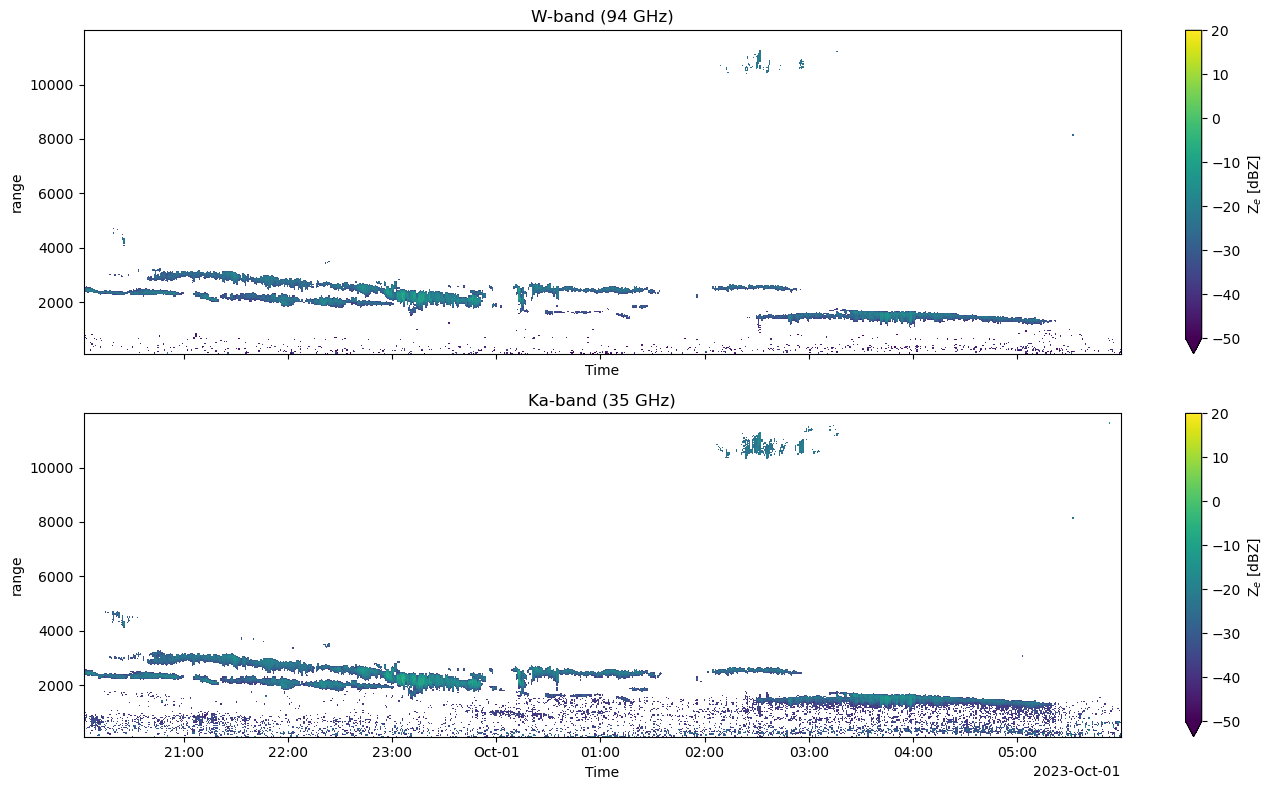

In [20]:
# Cell 8 — Side-by-side plot
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True, sharey=True)
ze_w_c.plot(x="Time", y="range", ax=axes[0], cmap="viridis", vmin=-50, vmax=20, cbar_kwargs={"label": "Z$_e$ [dBZ]"})
axes[0].set_title("W-band (94 GHz)")
ze_ka_c.plot(x="Time", y="range", ax=axes[1], cmap="viridis", vmin=-50, vmax=20, cbar_kwargs={"label": "Z$_e$ [dBZ]"})
axes[1].set_title("Ka-band (35 GHz)")
plt.tight_layout()
plt.show()

(array([3.0000e+00, 0.0000e+00, 4.0000e+00, 2.0000e+00, 4.0000e+00,
        3.0000e+00, 1.7000e+01, 1.1000e+01, 1.5000e+01, 2.4000e+01,
        4.2000e+01, 1.3800e+02, 6.3100e+02, 1.5050e+03, 2.7320e+03,
        4.3990e+03, 6.1810e+03, 8.1890e+03, 9.8860e+03, 1.1141e+04,
        1.2005e+04, 1.2599e+04, 1.2514e+04, 1.2364e+04, 1.2130e+04,
        1.1646e+04, 1.1258e+04, 1.0659e+04, 1.0256e+04, 9.8020e+03,
        9.4710e+03, 9.0980e+03, 8.8950e+03, 8.8660e+03, 8.5590e+03,
        8.4640e+03, 8.3270e+03, 8.2350e+03, 8.3710e+03, 8.5030e+03,
        8.7370e+03, 8.9360e+03, 8.4730e+03, 8.4550e+03, 8.0220e+03,
        7.4600e+03, 6.7720e+03, 5.8790e+03, 5.1560e+03, 4.3120e+03,
        3.7010e+03, 3.0710e+03, 2.5170e+03, 2.1220e+03, 1.8610e+03,
        1.5650e+03, 1.3690e+03, 1.0520e+03, 7.3800e+02, 5.5600e+02,
        4.9100e+02, 4.2000e+02, 3.7600e+02, 3.1900e+02, 2.8000e+02,
        2.0700e+02, 1.3000e+02, 9.6000e+01, 7.4000e+01, 6.2000e+01,
        3.5000e+01, 3.5000e+01, 4.4000e+01, 1.60

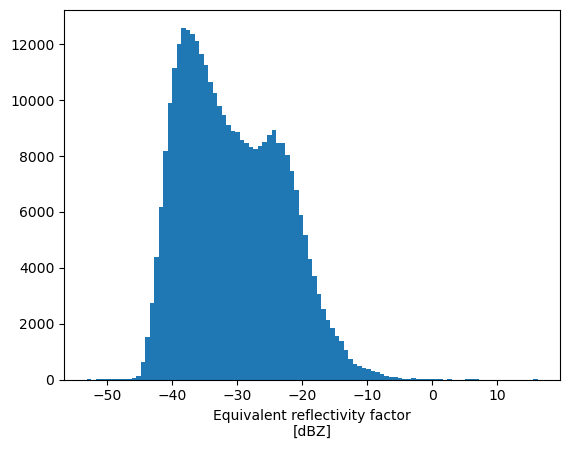

In [21]:
ze_ka.plot.hist(bins=100)

TEMPERATURE

In [22]:
T = ds_w["TProf"]                     # whatever the variable is named
print("Shape:", T.shape)                 # (Time, TAlt)?
print("Dims:", T.dims)
print("Min/Max:", float(T.min()), float(T.max()))
print("First profile (first time, all altitudes):")
print(T.isel(Time=0).values)
print("Altitude coord (if any):")
print(ds_w.coords)  # look for TAltLayer or similar


Shape: (14915, 93)
Dims: ('Time', 'TAlt')
Min/Max: 227.70535278320312 289.70269775390625
First profile (first time, all altitudes):
[288.79117 288.95    289.17126 289.4807  289.63525 289.63263 289.53906
 289.35687 289.1238  288.81628 288.48615 288.1447  287.79407 287.44232
 287.0944  286.76016 286.43796 286.1211  285.80997 285.51324 285.14877
 284.81082 284.4892  284.18164 283.9076  283.66635 283.4371  283.21408
 283.00604 282.83432 282.6967  282.57486 282.46017 282.34613 282.23874
 282.15894 282.099   282.01666 281.94974 281.8803  281.83456 281.79028
 281.75336 281.72656 281.67398 281.60104 281.51624 281.38596 281.2397
 280.80237 280.56107 280.27957 280.00616 279.76688 279.40897 279.03256
 278.62094 278.19772 277.7729  277.35568 276.92706 276.4816  276.03424
 275.57706 274.86072 274.10883 273.3583  272.57623 271.78104 270.98624
 270.18106 269.9038  268.76044 267.608   266.45306 265.26254 264.11816
 262.9264  261.66473 259.75345 257.76367 255.7236  253.658   251.44272
 249.23103 246.93

==================================================================================================================================================

The T Profile Values are interpolated onto the Range grid. First we have to get the altitudes for the Temperature Profile in T_Alts, because Temperature Profile T_Prof only has Indices 1,2,3,.... Afterwards T_Prof uses T_Alts Altitudes and then the Values are interpolated onto the range grid

==================================================================================================================================================

In [23]:
# Physical altitude of radiometer profile
T_alts = ds_w["TAlts"].isel(Time=0).values
assert np.allclose(ds_w["TAlts"].values, T_alts), "TAlts varies in time!"   # T_Alts is only at time 0 and it is compared to all the rest of data in TAlts. If it is not the same, then it will raise an error. This is to ensure that the altitude values are consistent across all time steps.

# Tell xarray these are the heights of TProf  --> I give T_Prof new Altitude Values because it just as 1,2,3,4... as indice instead of actual heights
T_prof = ds_w["TProf"].assign_coords(TAlt=("TAlt", T_alts))

# Interpolate onto radar gates
T_on_range = T_prof.interp(
    TAlt=ze_w_c["range"],
    method="linear"
)

T_on_range.name = "T_cloud"

In [24]:
print(T_on_range.shape)                                # should match ze_w_c.shape
print(f"{float(T_on_range.min()):.1f} → {float(T_on_range.max()):.1f} °K")
# Expect roughly: -60 → +20 °C  for Cabauw autumn

(14915, 339)
227.9 → 289.7 °K


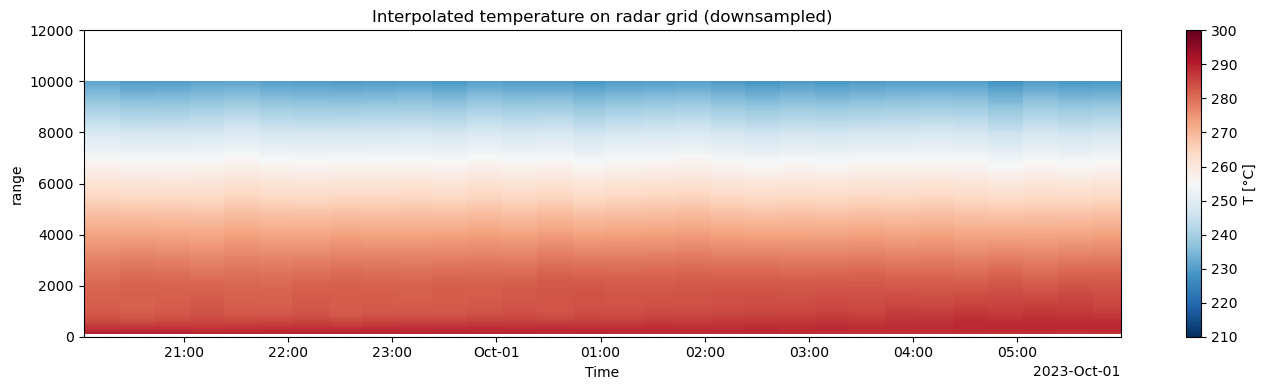

In [25]:

fig, ax = plt.subplots(1, 1, figsize=(14, 4))

T_on_range.isel(Time=slice(0, None, 5)).plot(
    x="Time",
    y="range",
    ax=ax,
    cmap="RdBu_r",
    vmin=210,
    vmax=300,
    cbar_kwargs={"label": "T [°C]"},
)

ax.axhline(0, ls="--", c="k", lw=0.8, alpha=0.5)
ax.set_ylim(0, 12000)
ax.set_title("Interpolated temperature on radar grid (downsampled)")

plt.tight_layout()
plt.show()


HUMIDITY FOR DATA SAVING

The AH Profile Values are interpolated onto the Range grid. First we have to get the altitudes for the Humidity Profile in HAlts, because Humidity Profile AHProf only has Indices 1,2,3,.... in HAlt.       Afterwards AH_Prof uses HAlts Altitudes and then the Values are interpolated onto the range grid

In [26]:
AH_alts = ds_w["HAlts"].isel(Time=0).values
assert np.allclose(ds_w["HAlts"].values, AH_alts), "HAlts varies in time!"   # AH_Alts is only at time 0 and it is compared to all the rest of data in HAlts. If it is not the same, then it will raise an error. This is to ensure that the altitude values are consistent across all time steps.

# Tell xarray these are the heights of AHProf  --> I give H_Prof new Altitude Values because it just as 1,2,3,4... as indice instead of actual heights
AH_prof = ds_w["AHProf"].assign_coords(HAlt=("HAlt", AH_alts))      #  HAlt gets new name which is the same as the original HAlts, but now it is assigned to the real Altitude variables.

# Interpolate onto radar gates
AH_on_range = AH_prof.interp(
    HAlt=ze_w_c["range"],
    method="linear"
)


AH_on_range.name = "AH_cloud"

In [27]:
print(AH_on_range)
print(AH_on_range.dims)
print(AH_on_range.shape)

<xarray.DataArray 'AH_cloud' (Time: 14915, range: 339)> Size: 20MB
dask.array<chunked_aware_interpnd, shape=(14915, 339), dtype=float32, chunksize=(78, 339), chunktype=numpy.ndarray>
Coordinates:
  * Time     (Time) datetime64[ns] 119kB 2023-09-30T20:02:27 ... 2023-10-01T0...
    HAlt     (range) float32 1kB 111.8 134.2 156.5 ... 1.194e+04 1.197e+04
  * range    (range) float32 1kB 111.8 134.2 156.5 ... 1.194e+04 1.197e+04
Attributes:
    Name:     Absolute humidity profiles from RPG radiometer
    Units:    g/m^3
('Time', 'range')
(14915, 339)


LWP FOR DATA SAVING

In [28]:
lwp = ds_w["LWP"]  # adjust name if needed
print(lwp)

<xarray.DataArray 'LWP' (Time: 14915)> Size: 60kB
dask.array<getitem, shape=(14915,), dtype=float32, chunksize=(78,), chunktype=numpy.ndarray>
Coordinates:
  * Time     (Time) datetime64[ns] 119kB 2023-09-30T20:02:27 ... 2023-10-01T0...
Attributes:
    Name:     Liquid water path
    Units:    g/m^2


PRESSURE FOR DATA SAVING

In [29]:
p_surf = ds_w["SurfPres"]
print(p_surf)
print(p_surf.shape)

<xarray.DataArray 'SurfPres' (Time: 14915)> Size: 60kB
dask.array<getitem, shape=(14915,), dtype=float32, chunksize=(78,), chunktype=numpy.ndarray>
Coordinates:
  * Time     (Time) datetime64[ns] 119kB 2023-09-30T20:02:27 ... 2023-10-01T0...
Attributes:
    Name:     Surface atmospheric pressure from weather station
    Units:    hPa
(14915,)


exponential atmosphere (constant scale height)

In [30]:
# Surface pressure (hPa)
surface_pressure = ds_w["SurfPres"].sel(Time=common_times).values

# Radar heights (m)
radar_range = ze_w_c["range"].values

# Create an empty array for the pressure profile
pressure_profile = np.zeros((len(ze_w_c.Time), len(ze_w_c.range)))

# Atmospheric scale height (m)
scale_height = 8000.0     #H=R_d*​T/g​       8000 for T= 273K ; At 288 K --> H=8427 m     ; At 250 K --> H=7310 m          Couple % difference and more in higher regions of clouds. In lower just a few % difference.

# Loop over all time steps
for t in range(len(surface_pressure)):

    # Surface pressure at this time
    p0 = surface_pressure[t]

    # Loop over all radar gates
    for r in range(len(radar_range)):

        height = radar_range[r]

        pressure_profile[t, r] = p0 * np.exp(-height / scale_height)

# Convert to xarray
P_cloud = xr.DataArray(
    pressure_profile,
    coords={
        "Time": ze_w_c["Time"],
        "range": ze_w_c["range"]
    },
    dims=("Time", "range"),
    name="P_cloud"
)

P_cloud.attrs["units"] = "hPa"
P_cloud.attrs["long_name"] = "Pressure profile"

In [31]:
print(P_cloud)
print(P_cloud.dims)
print(P_cloud.shape)

<xarray.DataArray 'P_cloud' (Time: 14915, range: 339)> Size: 40MB
array([[1010.47991943, 1007.65966797, 1004.84735107, ...,  231.53129578,
         230.44398499,  229.36183167],
       [1010.47991943, 1007.65966797, 1004.84735107, ...,  231.53129578,
         230.44398499,  229.36183167],
       [1010.47991943, 1007.65966797, 1004.84735107, ...,  231.53129578,
         230.44398499,  229.36183167],
       ...,
       [1008.21191406, 1005.39801025, 1002.59197998, ...,  231.0116272 ,
         229.92675781,  228.84703064],
       [1008.21191406, 1005.39801025, 1002.59197998, ...,  231.0116272 ,
         229.92675781,  228.84703064],
       [1008.21191406, 1005.39801025, 1002.59197998, ...,  231.0116272 ,
         229.92675781,  228.84703064]], shape=(14915, 339))
Coordinates:
  * Time     (Time) datetime64[ns] 119kB 2023-09-30T20:02:27 ... 2023-10-01T0...
  * range    (range) float32 1kB 111.8 134.2 156.5 ... 1.194e+04 1.197e+04
Attributes:
    units:      hPa
    long_name:  Pressure pro

Hypsometric Equation

In [32]:
# # Physical constants
# g = 9.80665          # m/s²
# R_d = 287.05         # J/(kg K)

# # Surface pressure (hPa)
# surface_pressure = ds_w["SurfPres"]

# # Radar heights (m)
# radar_range = ze_w_c["range"].values

# # Temperature on the radar grid (K)
# temperature = T_on_range.values

# # Create an empty array
# pressure_profile = np.zeros(
#     temperature.shape,
#     dtype=np.float32
# )

# # Loop over every radar profile
# for t in range(len(surface_pressure)):

#     # Pressure at the first radar gate
#     pressure_profile[t, 0] = surface_pressure.values[t]

#     # Loop upward through the atmosphere
#     for r in range(1, len(radar_range)):

#         # Height difference between two radar gates
#         dz = radar_range[r] - radar_range[r - 1]

#         # Mean temperature between the two gates
#         T_mean = 0.5 * (
#             temperature[t, r] +
#             temperature[t, r - 1]
#         )

#         # Pressure at the current gate
#         pressure_previous = pressure_profile[t, r - 1]

#         # Hypsometric equation
#         pressure_profile[t, r] = (
#             pressure_previous *
#             np.exp(-g * dz / (R_d * T_mean))
#         )

# # Convert to xarray
# P_cloud = xr.DataArray(
#     pressure_profile,
#     coords={
#         "Time": ze_w_c["Time"],
#         "range": ze_w_c["range"]
#     },
#     dims=("Time", "range"),
#     name="P_cloud"
# )

# P_cloud.attrs["units"] = "hPa"
# P_cloud.attrs["long_name"] = "Pressure profile"

Mean Doppler Velocities

In [33]:
# %% Combine MeanVel chirps (01_data_loading or wherever ZE combine happens)
MeanVel_W  = combine_chirps(ds_w,  var_prefix="MeanVel")
MeanVel_Ka = combine_chirps(ds_ka, var_prefix="MeanVel")

In [34]:
print(MeanVel_W.shape)
print(MeanVel_Ka.shape)

(14915, 339)
(14916, 339)


In [35]:
MeanVel_Ka_c = MeanVel_Ka.sel(Time=common_times)      # Both are set to the common  time ; .sel selects only the data whose Time coordinates match the Time coordinates of ze_w.
MeanVel_W_c = MeanVel_W.sel(Time=common_times)

In [36]:
print(f"After alignment: W={MeanVel_W_c.shape}, Ka={MeanVel_Ka_c.shape}")
assert MeanVel_W_c.shape == MeanVel_Ka_c.shape, "Shapes still don't match!"
print("✅ Aligned on common (time, range) grid")

After alignment: W=(14915, 339), Ka=(14915, 339)
✅ Aligned on common (time, range) grid


Sensitivity Limits

In [37]:
# %%
SLv_W  = combine_chirps(ds_w,  var_prefix="SLv")
SLv_Ka = combine_chirps(ds_ka, var_prefix="SLv")

# %%
print(SLv_W.shape)
print(SLv_Ka.shape)

# %%
SLv_Ka_c = SLv_Ka.sel(Time=common_times)
SLv_W_c  = SLv_W.sel(Time=common_times)

# %%
print(f"After alignment: W={SLv_W_c.shape}, Ka={SLv_Ka_c.shape}")
assert SLv_W_c.shape == SLv_Ka_c.shape, "Shapes still don't match!"
print("✅ Aligned on common (time, range) grid")

(14915, 339)
(14916, 339)
After alignment: W=(14915, 339), Ka=(14915, 339)
✅ Aligned on common (time, range) grid


In [38]:
SLh_W  = combine_chirps(ds_w,  var_prefix="SLh")
SLh_Ka = combine_chirps(ds_ka, var_prefix="SLh")

# %%
print(SLh_W.shape)
print(SLh_Ka.shape)

# %%
SLh_Ka_c = SLh_Ka.sel(Time=common_times)
SLh_W_c  = SLh_W.sel(Time=common_times)

# %%
print(f"After alignment: W={SLh_W_c.shape}, Ka={SLh_Ka_c.shape}")
assert SLh_W_c.shape == SLh_Ka_c.shape, "Shapes still don't match!"
print("✅ Aligned on common (time, range) grid")

(14915, 339)
(14916, 339)
After alignment: W=(14915, 339), Ka=(14915, 339)
✅ Aligned on common (time, range) grid


==================================================================================================================================================

SAVE DATA

==================================================================================================================================================

In [39]:
# Cell FINAL — Save aligned.nc
ds_out = xr.Dataset(
    {
        "SLh_W":    SLh_W_c.rename("SLh_W"),
        "SLh_Ka":    SLh_Ka_c.rename("SLh_Ka"),
        "SLv_W":    SLv_W_c.rename("SLv_W"),
        "SLv_Ka":    SLv_Ka_c.rename("SLv_Ka"),
        "MeanVel_W":    MeanVel_W_c.rename("MeanVel_W"),
        "MeanVel_Ka":    MeanVel_Ka_c.rename("MeanVel_Ka"),
        "Ze_W":    ze_w_c.rename("Ze_W"),
        "Ze_Ka":   ze_ka_c.rename("Ze_Ka"),
        "T_cloud": T_on_range,
        "AH_cloud": AH_on_range,
        "P_cloud":  P_cloud,
        "LWP":     lwp,
    },
    attrs={
        "description": "Aligned W/Ka reflectivities + T field for LWC retrieval",
        "date": "20230928",
        "site": "Cabauw",
        "Ze_units": "dBZ",
        "P_units": "hPa",
        "MeanVel_units": "m/s",
        "created_by": "02_align.ipynb",
    }
)
out_path = Path(f"../data/processed/{Processed_Dataset}/aligned_LWP2.nc")
out_path.parent.mkdir(parents=True, exist_ok=True)
ds_out.to_netcdf(out_path)
print(f"Saved → {out_path}")
print(ds_out)


Saved → ..\data\processed\20230930\aligned_LWP2.nc
<xarray.Dataset> Size: 243MB
Dimensions:     (Time: 14915, range: 339)
Coordinates:
  * Time        (Time) datetime64[ns] 119kB 2023-09-30T20:02:27 ... 2023-10-0...
  * range       (range) float32 1kB 111.8 134.2 156.5 ... 1.194e+04 1.197e+04
    TAlt        (range) float32 1kB 111.8 134.2 156.5 ... 1.194e+04 1.197e+04
    HAlt        (range) float32 1kB 111.8 134.2 156.5 ... 1.194e+04 1.197e+04
Data variables:
    SLh_W       (Time, range) float32 20MB dask.array<chunksize=(78, 22), meta=np.ndarray>
    SLh_Ka      (Time, range) float32 20MB dask.array<chunksize=(77, 22), meta=np.ndarray>
    SLv_W       (Time, range) float32 20MB dask.array<chunksize=(78, 22), meta=np.ndarray>
    SLv_Ka      (Time, range) float32 20MB dask.array<chunksize=(77, 22), meta=np.ndarray>
    MeanVel_W   (Time, range) float32 20MB dask.array<chunksize=(78, 22), meta=np.ndarray>
    MeanVel_Ka  (Time, range) float32 20MB dask.array<chunksize=(77, 22), meta=

In [40]:
# Check if LWP exists in Ka dataset
print("Ka variables:")
print(ds_ka.data_vars)

print("\nW variables:")
print(ds_w.data_vars)

Ka variables:
Data variables:
    TAlts      (Time, TAlt) float32 6MB dask.array<chunksize=(78, 93), meta=np.ndarray>
    HAlts      (Time, HAlt) float32 6MB dask.array<chunksize=(78, 93), meta=np.ndarray>
    SurfPres   (Time) float32 60kB dask.array<chunksize=(78,), meta=np.ndarray>
    LWP        (Time) float32 60kB dask.array<chunksize=(78,), meta=np.ndarray>
    TProf      (Time, TAlt) float32 6MB dask.array<chunksize=(78, 93), meta=np.ndarray>
    AHProf     (Time, HAlt) float32 6MB dask.array<chunksize=(78, 93), meta=np.ndarray>
    C1SLv      (Time, C1Range) float32 1MB dask.array<chunksize=(78, 22), meta=np.ndarray>
    C1SLh      (Time, C1Range) float32 1MB dask.array<chunksize=(78, 22), meta=np.ndarray>
    C2SLv      (Time, C2Range) float32 3MB dask.array<chunksize=(78, 52), meta=np.ndarray>
    C2SLh      (Time, C2Range) float32 3MB dask.array<chunksize=(78, 52), meta=np.ndarray>
    C3SLv      (Time, C3Range) float32 16MB dask.array<chunksize=(78, 265), meta=np.ndarray>
 

Trying Things